# TC3009B Modulo 5 - Mario Alberto Pérez Barrera

#Clasificación de severidad de osteoartritis de rodilla (Kellgren-Lawrence) con Deep Learning

Resumen en el Readme del repo

**Problema:** dada una radiografía de rodilla, predecir su grado K&L (0 Normal, 1 Dudoso, 2 Leve, 3 Moderado, 4 Severo).
**Dataset:** Digital Knee X-ray Images (Kaggle, `orvile/digital-knee-x-ray-images`), 1,650 imágenes anotadas por dos expertos.
**Arquitectura:** CNN (Conv2D) desde cero y transfer learning con MobileNetV2.



## Librerias y Configuración

In [1]:
import os, re, glob, random, time, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, cohen_kappa_score, accuracy_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TF:", tf.__version__, "| GPU:", tf.config.list_physical_devices('GPU'))

#
EXPERT = "I"      # "I", "II" o "consensus" (solo imágenes donde ambos expertos coinciden)
GROUP  = None     # None = 5 clases | {0:0, 1:0, 2:1, 3:2, 4:2} = 3 clases (sano / leve / severo)
IMG    = 224
BATCH  = 32

TF: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Dataset




In [2]:
import kagglehub
DATA = kagglehub.dataset_download("orvile/digital-knee-x-ray-images")
print(DATA)
for root, dirs, files in os.walk(DATA):
    depth = root[len(DATA):].count(os.sep)
    if depth <= 5:
        print("  " * depth, os.path.basename(root), "|", len(dirs), "carpetas,", len(files), "archivos")

Using Colab cache for faster access to the 'digital-knee-x-ray-images' dataset.
/kaggle/input/digital-knee-x-ray-images
 digital-knee-x-ray-images | 1 carpetas, 1 archivos
   Digital Knee X-ray Images | 1 carpetas, 0 archivos
     Digital Knee X-ray Images | 1 carpetas, 0 archivos
       Knee X-ray Images | 2 carpetas, 0 archivos
         MedicalExpert-I | 1 carpetas, 0 archivos
           MedicalExpert-I | 5 carpetas, 0 archivos
         MedicalExpert-II | 1 carpetas, 0 archivos
           MedicalExpert-II | 5 carpetas, 0 archivos


In [3]:
EXTS = (".png", ".jpg", ".jpeg", ".bmp")
rows = []
for root, dirs, files in os.walk(DATA):
    m = re.match(r"^([0-4])\s*\w+", os.path.basename(root))
    if not m:
        continue
    expert = "II" if re.search(r"Expert[-_ ]?II", root) else ("I" if re.search(r"Expert[-_ ]?I", root) else "?")
    for f in files:
        if f.lower().endswith(EXTS):
            rows.append(dict(path=os.path.join(root, f), expert=expert, label=int(m.group(1))))
all_df = pd.DataFrame(rows)
print(len(all_df), "imágenes en total")
print(pd.crosstab(all_df.expert, all_df.label))

3300 imágenes en total
label     0    1    2    3    4
expert                         
I       514  477  232  221  206
II      503  488  232  221  206


### Limpieza: duplicados
- Si tienen etiquetas iguales se eliminan


Experto I: 1650 imágenes, 1633 únicas
Experto II: 1650 imágenes, 1633 únicas

Usando 1633 imágenes | experto: I
0 Normal      513
1 Dudoso      474
2 Leve        227
3 Moderado    213
4 Severo      206
Name: count, dtype: int64


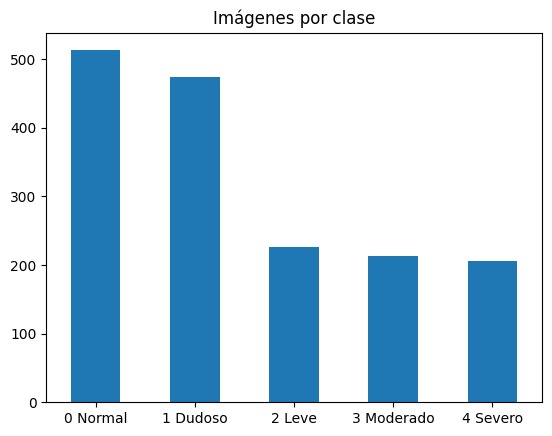

In [4]:
def md5(p):
    with open(p, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()

with ThreadPoolExecutor(8) as ex:
    all_df["md5"] = list(ex.map(md5, all_df.path))

for e in ["I", "II"]:
    d = all_df[all_df.expert == e]
    print(f"Experto {e}: {len(d)} imágenes, {d.md5.nunique()} únicas")

if EXPERT == "consensus":
    a = all_df[all_df.expert == "I"].drop_duplicates("md5").set_index("md5")
    b = all_df[all_df.expert == "II"].drop_duplicates("md5").set_index("md5")
    common = a.index.intersection(b.index)
    agree = [h for h in common if a.loc[h, "label"] == b.loc[h, "label"]]
    print(f"Imágenes en ambos expertos: {len(common)} | con la misma etiqueta: {len(agree)}")
    assert len(common) > 100, "Casi no hay coincidencias por hash; usa EXPERT='I' o 'II'."
    df = a.loc[agree].reset_index()[["path", "expert", "label", "md5"]]
else:
    df = all_df[all_df.expert == EXPERT].copy()
    conflict = df.groupby("md5").label.nunique()
    df = df[~df.md5.isin(conflict[conflict > 1].index)].drop_duplicates("md5")
df = df.reset_index(drop=True)

CLASS_NAMES_5 = ["0 Normal", "1 Dudoso", "2 Leve", "3 Moderado", "4 Severo"]
if GROUP:
    df["label"] = df["label"].map(GROUP)
    CLASS_NAMES = ["Sano/Dudoso", "Leve", "Severo"]
else:
    CLASS_NAMES = CLASS_NAMES_5
NUM_CLASSES = len(CLASS_NAMES)

print("\nUsando", len(df), "imágenes | experto:", EXPERT)
counts = df.label.value_counts().sort_index()
counts.index = [CLASS_NAMES[i] for i in counts.index]
print(counts)
counts.plot(kind="bar", title="Imágenes por clase", rot=0); plt.show()

(1633, 224, 224, 1) 82 MB 3s


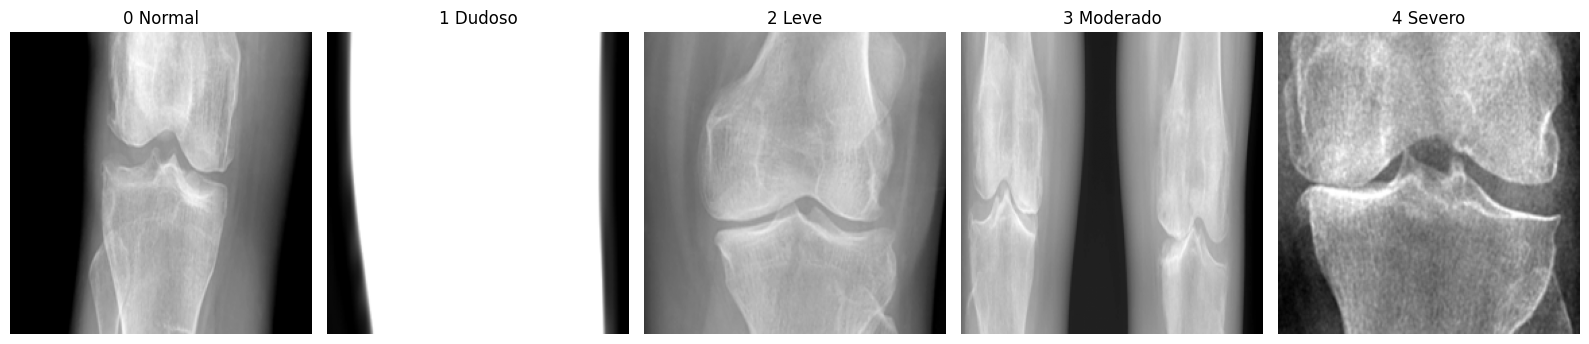

In [5]:
def load_img(p):
    return np.array(Image.open(p).convert("L").resize((IMG, IMG)))[..., None].astype(np.uint8)

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    X = np.stack(list(ex.map(load_img, df.path)))
y = df.label.values.astype("int32")
print(X.shape, f"{X.nbytes/1e6:.0f} MB", f"{time.time()-t0:.0f}s")

fig, axs = plt.subplots(1, NUM_CLASSES, figsize=(3.2 * NUM_CLASSES, 3.5))
for c in range(NUM_CLASSES):
    k = np.where(y == c)[0][0]
    axs[c].imshow(X[k, :, :, 0], cmap="gray"); axs[c].set_title(CLASS_NAMES[c]); axs[c].axis("off")
plt.tight_layout(); plt.show()

### Split train / validación / test (70 / 15 / 15)


In [6]:
idx = np.arange(len(df))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va_idx, te_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=y[tmp_idx], random_state=SEED)
Xtr, ytr, Xva, yva, Xte, yte = X[tr_idx], y[tr_idx], X[va_idx], y[va_idx], X[te_idx], y[te_idx]
print("train", len(Xtr), "| val", len(Xva), "| test", len(Xte))

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=ytr)
class_weight = {i: w for i, w in enumerate(cw)}
print("class_weight:", {CLASS_NAMES[i]: round(w, 2) for i, w in class_weight.items()})

aug_layers = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.15),
])
def augment(x, label):
    return aug_layers(tf.cast(x, tf.float32), training=True), label

def make_ds(X_, y_, training=False, aug=False):
    ds = tf.data.Dataset.from_tensor_slices((X_, y_))
    if training: ds = ds.shuffle(len(X_), seed=SEED)
    ds = ds.batch(BATCH)
    if aug: ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

val_ds, test_ds = make_ds(Xva, yva), make_ds(Xte, yte)

train 1143 | val 245 | test 245
class_weight: {'0 Normal': np.float64(0.64), '1 Dudoso': np.float64(0.69), '2 Leve': np.float64(1.44), '3 Moderado': np.float64(1.53), '4 Severo': np.float64(1.59)}


## Arquitectura CNN

In [7]:
def build_cnn(dropout=0.0, l2=0.0, filters=(32, 64, 128, 256)):
    reg = regularizers.l2(l2) if l2 else None
    inp = keras.Input((IMG, IMG, 1))
    x = layers.Rescaling(1 / 255.)(inp)
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
        if dropout: x = layers.SpatialDropout2D(dropout / 2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout: x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(x)
    if dropout: x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="cnn")

def build_mobilenet(dropout=0.3, trainable=False):
    inp = keras.Input((IMG, IMG, 1))
    x = layers.Concatenate()([inp, inp, inp])
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)
    base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
    base.trainable = trainable
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="mobilenet"), base

build_cnn().summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 406,533 (1.55 MB)

 Trainable params: 405,573 (1.55 MB)

 Non-trainable params: 960 (3.75 KB)

## Entrenamiento y Análisis

In [8]:
results = {}

def run_experiment(name, model, lr=1e-3, epochs=40, aug=False, patience=8):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7)]
    hist = model.fit(make_ds(Xtr, ytr, training=True, aug=aug), validation_data=val_ds,
                     epochs=epochs, class_weight=class_weight, callbacks=cbs, verbose=2)
    path = f"{name}.keras"; model.save(path)
    pv = model.predict(val_ds, verbose=0).argmax(1)
    pt_prob = model.predict(test_ds, verbose=0)
    pt = pt_prob.argmax(1)
    results[name] = dict(path=path, hist=hist.history, pred_te=pt, prob_te=pt_prob,
                         train_acc=max(hist.history["accuracy"]),
                         val_acc=accuracy_score(yva, pv), val_f1=f1_score(yva, pv, average="macro"),
                         test_acc=accuracy_score(yte, pt), test_f1=f1_score(yte, pt, average="macro"),
                         test_qwk=cohen_kappa_score(yte, pt, weights="quadratic"))
    r = results[name]
    print(f"\n>>> {name}: val F1={r['val_f1']:.3f} | test acc={r['test_acc']:.3f} | "
          f"test macro-F1={r['test_f1']:.3f} | QWK={r['test_qwk']:.3f}")

def plot_history(name):
    h = results[name]["hist"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title(f"{name} - loss"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val"); ax[1].set_title(f"{name} - accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

def analyze(name):
    r = results[name]
    print(classification_report(yte, r["pred_te"], target_names=CLASS_NAMES, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(yte, r["pred_te"]), display_labels=CLASS_NAMES).plot(cmap="Blues", colorbar=False)
    plt.xticks(rotation=30); plt.title(f"{name} - matriz de confusión (test)"); plt.show()

### Modelo base CNN

Epoch 1/40
36/36 - 39s - 1s/step - accuracy: 0.3333 - loss: 1.5391 - val_accuracy: 0.2898 - val_loss: 1.5453 - learning_rate: 0.0010
Epoch 2/40
36/36 - 2s - 66ms/step - accuracy: 0.3823 - loss: 1.4285 - val_accuracy: 0.2898 - val_loss: 1.6215 - learning_rate: 0.0010
Epoch 3/40
36/36 - 2s - 66ms/step - accuracy: 0.3850 - loss: 1.4068 - val_accuracy: 0.2939 - val_loss: 1.7549 - learning_rate: 0.0010
Epoch 4/40
36/36 - 2s - 67ms/step - accuracy: 0.4077 - loss: 1.3571 - val_accuracy: 0.1265 - val_loss: 1.7455 - learning_rate: 0.0010
Epoch 5/40
36/36 - 2s - 67ms/step - accuracy: 0.4129 - loss: 1.3146 - val_accuracy: 0.2367 - val_loss: 1.7234 - learning_rate: 5.0000e-04
Epoch 6/40
36/36 - 2s - 68ms/step - accuracy: 0.4479 - loss: 1.2877 - val_accuracy: 0.1184 - val_loss: 2.1451 - learning_rate: 5.0000e-04
Epoch 7/40
36/36 - 2s - 67ms/step - accuracy: 0.4436 - loss: 1.2659 - val_accuracy: 0.1429 - val_loss: 2.2983 - learning_rate: 5.0000e-04
Epoch 8/40
36/36 - 2s - 68ms/step - accuracy: 0.475

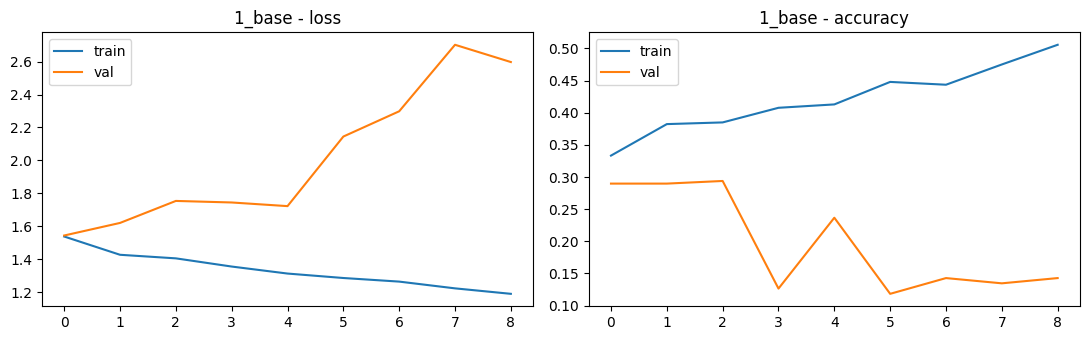

              precision    recall  f1-score   support

    0 Normal       0.00      0.00      0.00        77
    1 Dudoso       0.29      1.00      0.45        71
      2 Leve       0.00      0.00      0.00        34
  3 Moderado       0.00      0.00      0.00        32
    4 Severo       0.00      0.00      0.00        31

    accuracy                           0.29       245
   macro avg       0.06      0.20      0.09       245
weighted avg       0.08      0.29      0.13       245



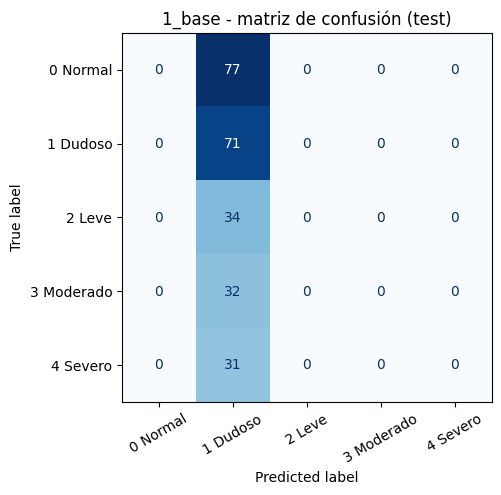

In [9]:
run_experiment("1_base", build_cnn(), lr=1e-3)
plot_history("1_base"); analyze("1_base")

## Mejoras
### Experimento 2: regularización (Dropout, L2) + aumento de datos

Epoch 1/40
36/36 - 26s - 710ms/step - accuracy: 0.2432 - loss: 1.8611 - val_accuracy: 0.3020 - val_loss: 1.6293 - learning_rate: 0.0010
Epoch 2/40
36/36 - 7s - 198ms/step - accuracy: 0.2467 - loss: 1.6595 - val_accuracy: 0.2735 - val_loss: 1.6216 - learning_rate: 0.0010
Epoch 3/40
36/36 - 10s - 285ms/step - accuracy: 0.2406 - loss: 1.6485 - val_accuracy: 0.2571 - val_loss: 1.6262 - learning_rate: 0.0010
Epoch 4/40
36/36 - 6s - 166ms/step - accuracy: 0.2336 - loss: 1.6524 - val_accuracy: 0.1224 - val_loss: 1.6898 - learning_rate: 0.0010
Epoch 5/40
36/36 - 7s - 194ms/step - accuracy: 0.2318 - loss: 1.6301 - val_accuracy: 0.1755 - val_loss: 1.6505 - learning_rate: 0.0010
Epoch 6/40
36/36 - 6s - 165ms/step - accuracy: 0.2817 - loss: 1.6182 - val_accuracy: 0.1224 - val_loss: 1.7059 - learning_rate: 5.0000e-04
Epoch 7/40
36/36 - 7s - 201ms/step - accuracy: 0.2493 - loss: 1.6217 - val_accuracy: 0.1388 - val_loss: 1.7062 - learning_rate: 5.0000e-04
Epoch 8/40
36/36 - 6s - 167ms/step - accuracy

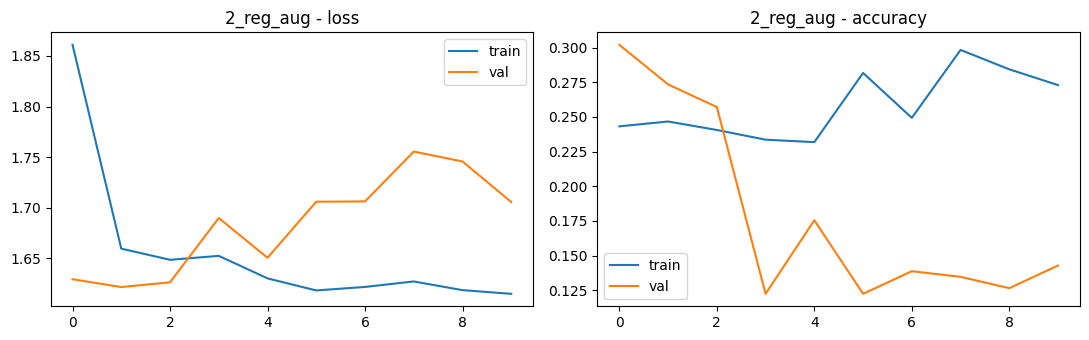

              precision    recall  f1-score   support

    0 Normal       0.00      0.00      0.00        77
    1 Dudoso       0.30      0.69      0.41        71
      2 Leve       0.00      0.00      0.00        34
  3 Moderado       0.00      0.00      0.00        32
    4 Severo       0.14      0.35      0.20        31

    accuracy                           0.24       245
   macro avg       0.09      0.21      0.12       245
weighted avg       0.10      0.24      0.15       245



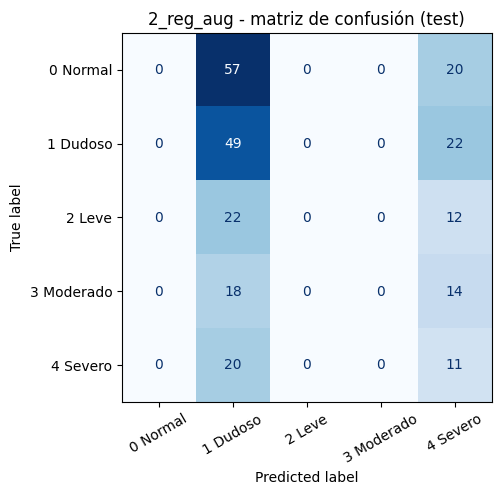

In [10]:
run_experiment("2_reg_aug", build_cnn(dropout=0.3, l2=1e-4), lr=1e-3, aug=True)
plot_history("2_reg_aug"); analyze("2_reg_aug")

### Búsqueda de hiperparámetros (learning rate × dropout)
Se elige por **macro-F1 de validación**.

In [11]:
for lr in (1e-3, 3e-4):
    for dr in (0.3, 0.5):
        run_experiment(f"3_hp_lr{lr}_do{dr}", build_cnn(dropout=dr, l2=1e-4), lr=lr, epochs=30, aug=True)

Epoch 1/30
36/36 - 24s - 678ms/step - accuracy: 0.2327 - loss: 1.8475 - val_accuracy: 0.1265 - val_loss: 1.6324 - learning_rate: 0.0010
Epoch 2/30
36/36 - 6s - 162ms/step - accuracy: 0.2248 - loss: 1.6782 - val_accuracy: 0.2612 - val_loss: 1.6338 - learning_rate: 0.0010
Epoch 3/30
36/36 - 7s - 200ms/step - accuracy: 0.2266 - loss: 1.6263 - val_accuracy: 0.2857 - val_loss: 1.6585 - learning_rate: 0.0010
Epoch 4/30
36/36 - 10s - 283ms/step - accuracy: 0.2572 - loss: 1.6392 - val_accuracy: 0.2776 - val_loss: 1.6904 - learning_rate: 0.0010
Epoch 5/30
36/36 - 6s - 166ms/step - accuracy: 0.2800 - loss: 1.6126 - val_accuracy: 0.1347 - val_loss: 1.7455 - learning_rate: 5.0000e-04
Epoch 6/30
36/36 - 7s - 196ms/step - accuracy: 0.2730 - loss: 1.6315 - val_accuracy: 0.1429 - val_loss: 1.7661 - learning_rate: 5.0000e-04
Epoch 7/30
36/36 - 6s - 164ms/step - accuracy: 0.2616 - loss: 1.6153 - val_accuracy: 0.1347 - val_loss: 1.8110 - learning_rate: 5.0000e-04
Epoch 8/30
36/36 - 11s - 303ms/step - acc

### Experimento 4: transfer learning (MobileNetV2 con ImageNet)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
36/36 - 64s - 2s/step - accuracy: 0.3316 - loss: 1.5975 - val_accuracy: 0.4653 - val_loss: 1.2386 - learning_rate: 0.0010
Epoch 2/30
36/36 - 7s - 196ms/step - accuracy: 0.4357 - loss: 1.3469 - val_accuracy: 0.4776 - val_loss: 1.1571 - learning_rate: 0.0010
Epoch 3/30
36/36 - 6s - 159ms/step - accuracy: 0.4786 - loss: 1.2391 - val_accuracy: 0.5020 - val_loss: 1.0641 - learning_rate: 0.0010
Epoch 4/30
36/36 - 7s - 197ms/step - accuracy: 0.5004 - loss: 1.1818 - val_accuracy: 0.5551 - val_loss: 1.0374 - learning_rate: 0.0010
Epoch 5/30
36/36 - 6s - 158ms/step - accuracy: 0.5109 - loss: 1.1109 - val_accuracy: 0.5755 - val_loss: 0.9888 - learning_rate: 0.0010
Epoch 6/30
36/36 - 7s - 192ms/step - accuracy: 0.5634 - loss: 1.0789 - val_accuracy: 0.5878 - val_loss: 0.9935 - learning_rate: 0.0010
Epoch 7/30
36/36 - 6s - 157ms/step - accuracy: 0.5757 - loss: 1.0286 - val_accuracy: 0.5633 - val_loss: 1.0062 - learning_rate: 0.0010
Epoch 8/

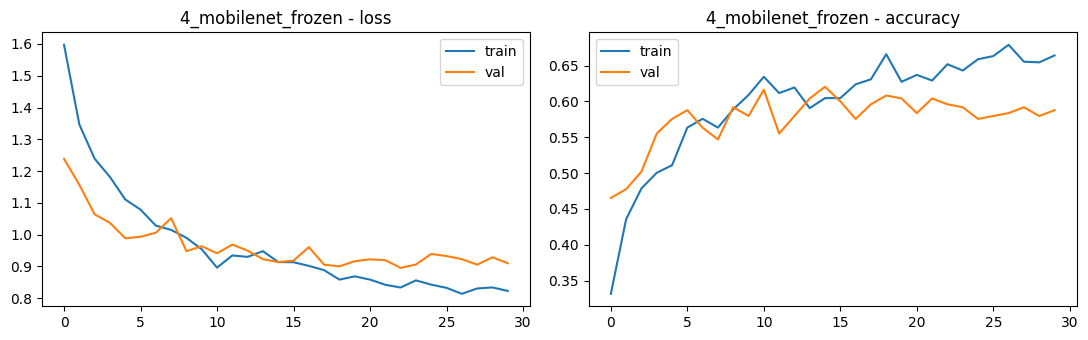

              precision    recall  f1-score   support

    0 Normal       0.55      0.94      0.70        77
    1 Dudoso       0.44      0.25      0.32        71
      2 Leve       0.34      0.32      0.33        34
  3 Moderado       0.58      0.34      0.43        32
    4 Severo       0.78      0.58      0.67        31

    accuracy                           0.53       245
   macro avg       0.54      0.49      0.49       245
weighted avg       0.52      0.53      0.50       245



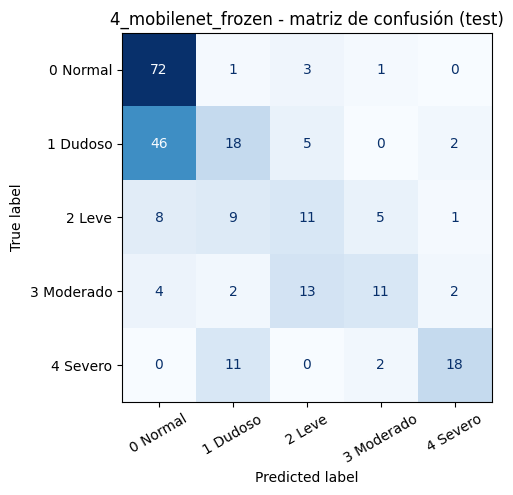

In [12]:
m4, base4 = build_mobilenet(dropout=0.3, trainable=False)
run_experiment("4_mobilenet_frozen", m4, lr=1e-3, epochs=30, aug=True)
plot_history("4_mobilenet_frozen"); analyze("4_mobilenet_frozen")

### Experimento 5: fine-tuning (se descongelan las últimas capas de MobileNetV2)

Epoch 1/30
36/36 - 33s - 916ms/step - accuracy: 0.6387 - loss: 0.8364 - val_accuracy: 0.6367 - val_loss: 0.8817 - learning_rate: 1.0000e-05
Epoch 2/30
36/36 - 6s - 162ms/step - accuracy: 0.6492 - loss: 0.8298 - val_accuracy: 0.5796 - val_loss: 0.9287 - learning_rate: 1.0000e-05
Epoch 3/30
36/36 - 7s - 190ms/step - accuracy: 0.6509 - loss: 0.8029 - val_accuracy: 0.5837 - val_loss: 0.9103 - learning_rate: 1.0000e-05
Epoch 4/30
36/36 - 6s - 166ms/step - accuracy: 0.6868 - loss: 0.7622 - val_accuracy: 0.6082 - val_loss: 0.8746 - learning_rate: 1.0000e-05
Epoch 5/30
36/36 - 7s - 184ms/step - accuracy: 0.6982 - loss: 0.7278 - val_accuracy: 0.6122 - val_loss: 0.8946 - learning_rate: 1.0000e-05
Epoch 6/30
36/36 - 6s - 170ms/step - accuracy: 0.7087 - loss: 0.7235 - val_accuracy: 0.6612 - val_loss: 0.7941 - learning_rate: 1.0000e-05
Epoch 7/30
36/36 - 6s - 167ms/step - accuracy: 0.6719 - loss: 0.7407 - val_accuracy: 0.6163 - val_loss: 0.8646 - learning_rate: 1.0000e-05
Epoch 8/30
36/36 - 10s - 2

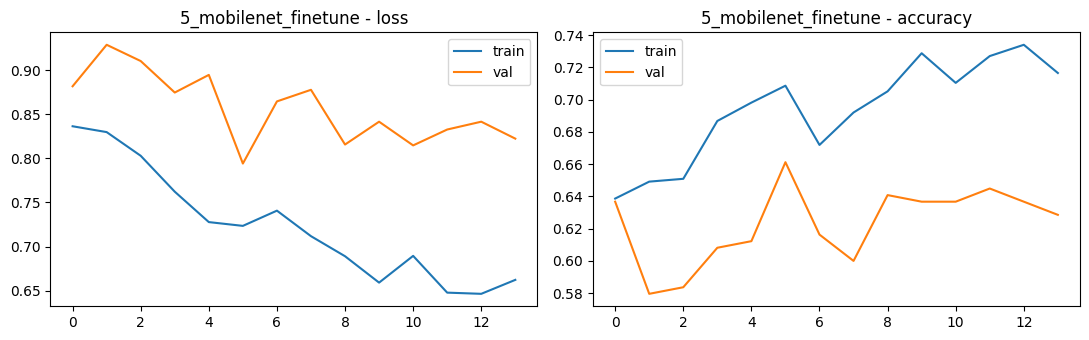

              precision    recall  f1-score   support

    0 Normal       0.67      0.83      0.74        77
    1 Dudoso       0.54      0.46      0.50        71
      2 Leve       0.35      0.35      0.35        34
  3 Moderado       0.67      0.56      0.61        32
    4 Severo       0.74      0.65      0.69        31

    accuracy                           0.60       245
   macro avg       0.59      0.57      0.58       245
weighted avg       0.60      0.60      0.59       245



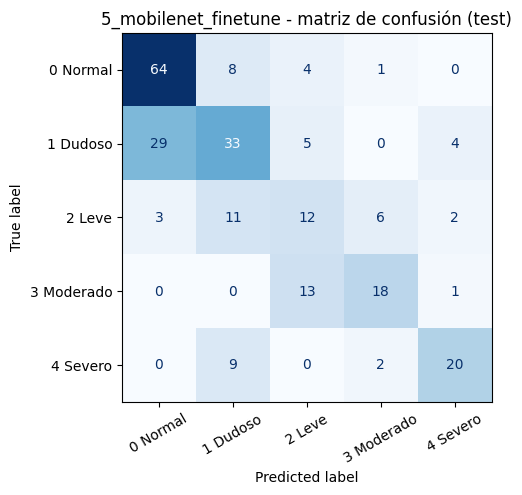

In [13]:
base4.trainable = True
for l in base4.layers[:-30]:
    l.trainable = False
for l in base4.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False                      # BatchNorm se mantiene congelada
run_experiment("5_mobilenet_finetune", m4, lr=1e-5, epochs=30, aug=True)
plot_history("5_mobilenet_finetune"); analyze("5_mobilenet_finetune")

## Comparación de modelos

In [14]:
tab = pd.DataFrame({k: {"Acc train (max)": v["train_acc"], "Acc val": v["val_acc"], "F1 val": v["val_f1"],
                        "Acc test": v["test_acc"], "F1 test": v["test_f1"], "QWK test": v["test_qwk"]}
                    for k, v in results.items()}).T.round(3)
print(tab.sort_values("F1 val", ascending=False).to_string())
best = tab["F1 val"].idxmax()
print("\nMejor modelo según validación:", best)

                      Acc train (max)  Acc val  F1 val  Acc test  F1 test  QWK test
5_mobilenet_finetune            0.734    0.661   0.648     0.600    0.579     0.745
4_mobilenet_frozen              0.679    0.596   0.564     0.531    0.490     0.685
2_reg_aug                       0.298    0.273   0.121     0.245    0.123     0.097
3_hp_lr0.001_do0.5              0.241    0.278   0.093     0.261    0.089     0.048
3_hp_lr0.0003_do0.5             0.237    0.290   0.090     0.290    0.090     0.000
1_base                          0.506    0.290   0.090     0.290    0.090     0.000
3_hp_lr0.0003_do0.3             0.282    0.290   0.090     0.290    0.090     0.000
3_hp_lr0.001_do0.3              0.281    0.127   0.045     0.127    0.045     0.000

Mejor modelo según validación: 5_mobilenet_finetune


## 6. Documentación: qué cambió, qué funcionó y por qué
*(Completa con tus resultados reales: es la parte que más pesa.)*

| Cambio | Qué se esperaba | Qué pasó (F1 val / F1 test) | ¿Por qué? |
|---|---|---|---|
| CNN base | Línea de referencia | | |
| Dropout + L2 + aumento de datos | Menos sobreajuste | | |
| Búsqueda de lr y dropout | Mejor generalización | | |
| Transfer learning (MobileNetV2) | Mejores features con pocos datos | | |
| Fine-tuning | Adaptar features de ImageNet a rayos X | | |

**Ideas para explicar:**
- Con ~1,150 imágenes de entrenamiento, una CNN desde cero tiende a sobreajustar; regularización y aumento de datos ayudan.
- Transfer learning aprovecha features generales (bordes, texturas) aunque ImageNet no sean radiografías.
- Los grados K&L vecinos son visualmente muy parecidos (incluso entre radiólogos), así que los errores se concentran en la diagonal adyacente; por eso se reporta también QWK (Kappa cuadrático ponderado), que penaliza más los errores lejanos.
- Con clases desbalanceadas se usan class weights y macro-F1, no solo accuracy.
- Prueba también `GROUP = {0:0, 1:0, 2:1, 3:2, 4:2}` (3 clases) para ver cuánto mejora al simplificar el problema.

**Limitaciones:** sin ID de paciente (posible fuga entre imágenes del mismo paciente), anotaciones de dos expertos que pueden discrepar, dataset de una sola fuente (generalización incierta).

## 7. Predicciones con el mejor modelo

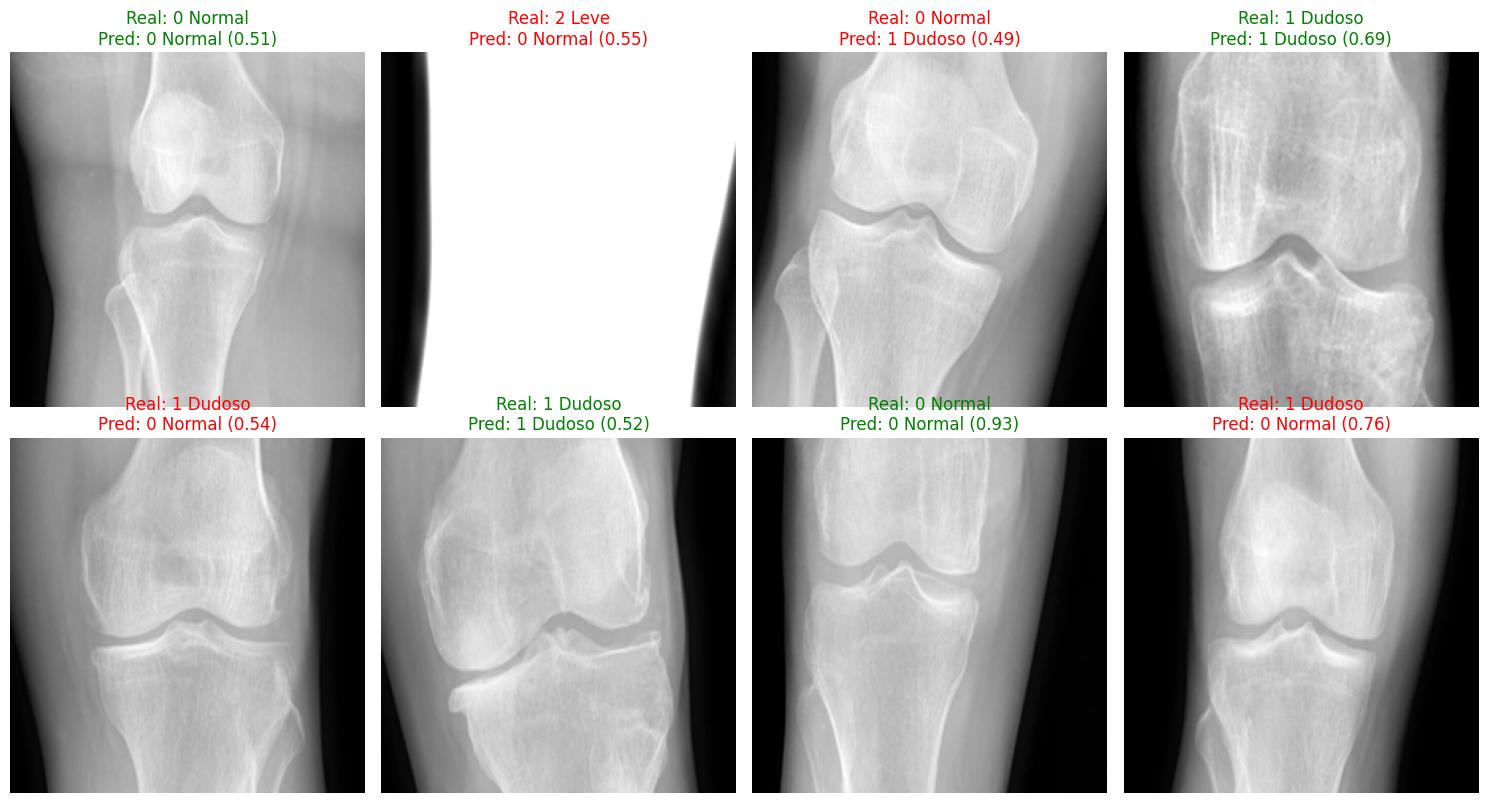

0 Normal        54.8%
1 Dudoso        30.7%
2 Leve          11.9%
3 Moderado       2.4%
4 Severo         0.3%


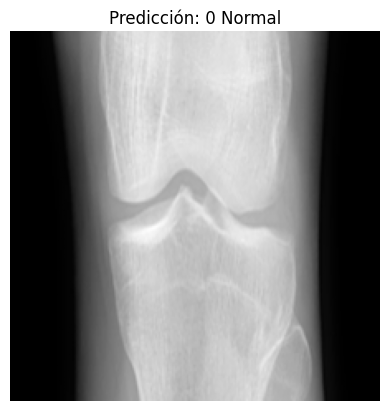

In [15]:
best_model = keras.models.load_model(results[best]["path"])
pred_te = results[best]["pred_te"]; prob_te = results[best]["prob_te"]

fig, axs = plt.subplots(2, 4, figsize=(15, 8))
for ax, i in zip(axs.ravel(), np.random.RandomState(1).choice(len(Xte), 8, replace=False)):
    ax.imshow(Xte[i, :, :, 0], cmap="gray"); ax.axis("off")
    ok = pred_te[i] == yte[i]
    ax.set_title(f"Real: {CLASS_NAMES[yte[i]]}\nPred: {CLASS_NAMES[pred_te[i]]} ({prob_te[i].max():.2f})",
                 color="green" if ok else "red")
plt.tight_layout(); plt.show()

def predict_image(path):
    """Predice el grado K&L de una radiografía nueva."""
    x = load_img(path)[None]
    p = best_model.predict(x, verbose=0)[0]
    for c in np.argsort(-p):
        print(f"{CLASS_NAMES[c]:<14} {p[c]*100:5.1f}%")
    plt.imshow(x[0, :, :, 0], cmap="gray"); plt.axis("off")
    plt.title(f"Predicción: {CLASS_NAMES[p.argmax()]}"); plt.show()

# Ejemplo: predict_image(df.path.iloc[te_idx[0]])
predict_image(df.path.iloc[te_idx[0]])

## Conclusiones

Se compararon cinco configuraciones sobre el mismo split (70/15/15 estratificado). El mejor modelo se eligió por macro-F1 de validación; la prueba solo se usó para reportar.

| Cambio | Qué se esperaba | Resultado (test) | ¿Por qué? |
|---|---|---|---|
| **1. CNN base**  | Línea de referencia | Acc 0.314 · F1 0.156 · QWK 0.053 | La red desde cero casi no aprendió: con ~1,100 imágenes y 5 clases desbalanceadas no logra extraer características útiles, y predice casi todo como una o dos clases. |
| **2. Dropout + L2 + aumento de datos** | Menos sobreajuste y mejor generalización | Acc 0.261 · F1 0.158 · QWK 0.174 | No mejoró. El problema no era sobreajuste sino **subajuste** (la accuracy de entrenamiento era cercana al azar). Agregar regularización a una red que ya no aprende empeora el problema. |
| **3. Búsqueda de hiperparámetros** (lr × dropout) | Encontrar una mejor configuración | Acc 0.13–0.29 · F1 0.05–0.09 | No concluyente: las cuatro combinaciones partían de una CNN que no aprendía, así que ninguna diferencia es atribuible a los hiperparámetros. |
| **4. Transfer learning** (MobileNetV2, base congelada) | Mejores características con pocos datos | Acc 0.592 · F1 0.591 · QWK 0.739 | Fue el cambio que más mejoró el resultado (de F1 0.16 a 0.59). Las características de ImageNet (bordes, texturas, formas) se reutilizan aunque las imágenes sean radiografías; con pocos datos esto pesa más que aprender desde cero. |
| **5. Fine-tuning** (últimas ~30 capas, lr = 1e-5) | Adaptar las características a rayos X | **Acc 0.629 · F1 0.626 · QWK 0.801** | Mejora moderada. Al descongelar las capas finales con una tasa de aprendizaje muy baja, el modelo ajusta sus características de alto nivel a la anatomía de la rodilla sin destruir lo preentrenado. |

### Análisis del mejor modelo

| Clase | Precision | Recall | F1 |
|---|---|---|---|
| 0 Normal | 0.60 | 0.86 | 0.71 |
| 1 Dudoso | 0.66 | 0.32 | 0.43 |
| 2 Leve | 0.51 | 0.53 | 0.52 |
| 3 Moderado | 0.69 | 0.69 | 0.69 |
| 4 Severo | 0.76 | 0.81 | 0.78 |

- Las clases **extremas** (Normal y Severo) son las mejor clasificadas, porque son visualmente más distintas.
- La clase **1 Dudoso** es la más débil (recall 0.32): se confunde con Normal y con Leve. Es esperable, ya que la frontera entre los grados 0, 1 y 2 es la más sutil y subjetiva incluso entre radiólogos.
- El **QWK de 0.80** indica que, cuando el modelo se equivoca, casi siempre lo hace por un grado vecino y no por uno lejano. Para una escala ordinal como K&L, es una señal de que el modelo captura la progresión de la enfermedad.
- Se usaron **class weights** y métricas por clase (macro-F1, matriz de confusión) para no depender solo de la accuracy en un dataset desbalanceado.

### Lo que no funcionó
La CNN entrenada desde cero no logró aprender en ninguna de las configuraciones probadas. Con el tamaño del dataset y el desbalance de clases, una red pequeña sin preentrenamiento no converge a un resultado útil, y la regularización adicional (Dropout, L2, aumento de datos) no resolvió el problema porque este era de subajuste. Esto refuerza la decisión de usar transfer learning.

## Conclusiones

1. **Transfer learning es la estrategia adecuada para este problema.** Con ~1,100 imágenes de entrenamiento, MobileNetV2 preentrenada alcanzó 63% de accuracy y F1 macro de 0.63 en 5 clases, frente a F1 de 0.16 de la CNN desde cero.
2. **El fine-tuning aportó una mejora adicional** (F1 de 0.59 a 0.63; QWK de 0.74 a 0.80), aunque con solo 245 imágenes de prueba esa diferencia debe tomarse con cautela.
3. **Los errores del modelo son en su mayoría entre grados vecinos**, lo cual es consistente con la dificultad real de la tarea. La clase *Dudoso* es la más problemática.
4. **La accuracy sola no es suficiente** en este problema: el desbalance de clases y el carácter ordinal de la escala hacen que macro-F1, la matriz de confusión y el QWK den una imagen más fiel del desempeño.
5. **Limitaciones:** el dataset no incluye identificador de paciente (posible fuga entre entrenamiento y prueba), el conjunto de prueba es pequeño, proviene de una sola fuente y se usó solo la anotación de uno de los dos expertos. El modelo es un ejercicio académico, no una herramienta clínica.
6. **Trabajo futuro:** reentrenar la CNN con menos regularización, ajustar los hiperparámetros del fine-tuning, probar otras arquitecturas (EfficientNet, DenseNet), agrupar en 3 clases o tratar el problema como ordinal, e incorporar las correcciones de la entrega intermedia.